# Viviendas turísticas por comunidad autónoma

In [ ]:
# Parámetros de la gráfica
SLUG = "vivienda"  # carpeta en research/temas/
GRAFICA_ID = "viviendas-uso-turistico"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Viviendas turísticas por comunidad autónoma"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "por_ccaa"  # serie_temporal | por_ccaa | solo_espana
VISTA = "ultimo_anio"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = 100  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% del total de viviendas"  # unidad del indicador
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** Qué parte de las viviendas de cada comunidad autónoma se ofrece como vivienda turística en las principales plataformas, según la estadística experimental del INE «Medición del número de viviendas turísticas en España y su capacidad».

**Cómo se lee.** Un valor de 1,5 significa que el 1,5 % de las viviendas censadas son viviendas turísticas. La línea gruesa es el total de España y las grises, las comunidades.

**Limitaciones.**
- Es una estadística experimental, elaborada con datos de plataformas en línea.
- El INE publica dos datos al año y ha cambiado los meses de referencia; aquí se toma el último dato publicado, y el turismo es estacional, así que el porcentaje depende del mes de referencia y no es comparable con el de otras fechas. El dato del año en curso es provisional.

## 2. Descarga

INE, tabla 39365 (porcentaje de viviendas turísticas sobre el total de viviendas censadas): una serie por comunidad autónoma y el total nacional. El fetcher toma el último dato publicado de cada año (`ultimo_disponible`).

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from lib import ine

SERIES = {'VTE287': 'espana', 'VTE286': 'ES-AN', 'VTE285': 'ES-AR', 'VTE284': 'ES-AS', 'VTE283': 'ES-IB', 'VTE282': 'ES-CN', 'VTE281': 'ES-CB', 'VTE280': 'ES-CL', 'VTE279': 'ES-CM', 'VTE278': 'ES-CT', 'VTE277': 'ES-VC', 'VTE276': 'ES-EX', 'VTE275': 'ES-GA', 'VTE274': 'ES-MD', 'VTE273': 'ES-MC', 'VTE272': 'ES-NC', 'VTE271': 'ES-PV', 'VTE270': 'ES-RI', 'VTE269': 'ES-CE', 'VTE268': 'ES-ML'}  # código INE -> id de serie (config.json, datasets)


def descargar():
    """Devuelve (DataFrame `serie, periodo, valor`, lista de FuenteMeta)."""
    return ine.get(SERIES, agregacion="ultimo_disponible", desde=DESDE)


df, fuentes = descargar()

## 3. Transformación

Los datos ya vienen en la unidad final.

In [ ]:
ULTIMO = int(df["periodo"].max())
NOTAS = [
    "INE, estadística experimental «Medición del número de viviendas turísticas en España y su capacidad» (tabla 39365): porcentaje de viviendas turísticas sobre el total de viviendas censadas.",
    "El INE publica dos datos al año y ha cambiado los meses de referencia; se toma el último dato publicado. Como el turismo es estacional, el porcentaje depende del mes de referencia y no es comparable con el de otras fechas ni con el de otras estadísticas.",
    f"El dato de {ULTIMO} es provisional: puede cambiar cuando el INE publique el siguiente del año.",
]

## 4. Visualización

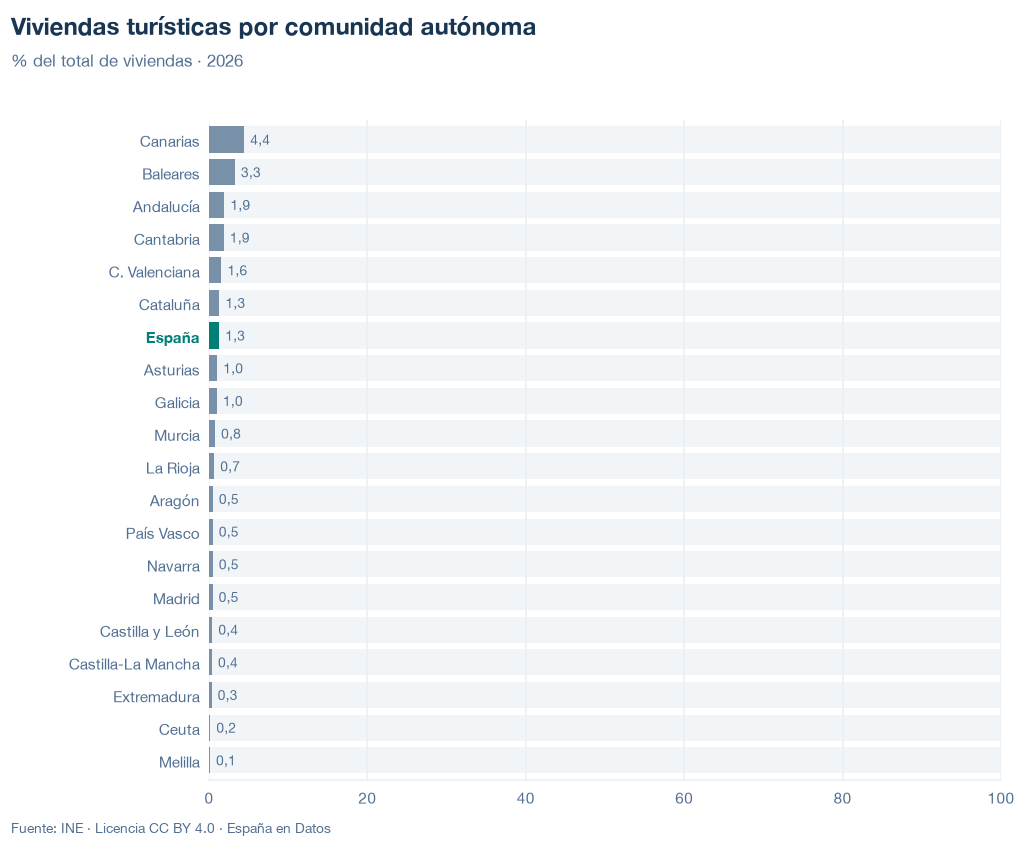

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/viviendas-uso-turistico.json y data/viviendas-uso-turistico.csv


## 6. Fuentes, notas y licencia

- INE, tabla 39365 (series `VTE268` a `VTE287`).

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.